# **Upload a image with name 'test.png' and click Run all**


In [48]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow # Special function for Colab to show images
import requests # To download a sample image

In [49]:
def exact_adder_8bit(a, b):
    # Both a and b are treated as unsigned 8-bit integers
    return (int(a) & 0xFF) + (int(b) & 0xFF)

def apply_exact_mean_filter(image):
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    padded = cv2.copyMakeBorder(image, 1, 1, 1, 1, cv2.BORDER_REFLECT)
    output = np.zeros_like(image)

    rows, cols = image.shape
    for i in range(1, rows + 1):
        for j in range(1, cols + 1):
            roi = padded[i-1:i+2, j-1:j+2].flatten()

            total = 0
            for val in roi:
                total = exact_adder_8bit(total, val)

            # The result is divided by 9 for the mean filter
            output[i-1, j-1] = total // 9

    return output

In [50]:
def approximate_adder_8bit(a, b, split_point=4):
    a = int(a) & 0xFF  # clamp to 8 bits
    b = int(b) & 0xFF  # clamp to 8 bits

    a_bin = format(a, '08b')
    b_bin = format(b, '08b')

    acc_a, app_a = a_bin[:split_point], a_bin[split_point:]
    acc_b, app_b = b_bin[:split_point], b_bin[split_point:]

    res_app = ""
    stuck_at_one = False
    for bit_a, bit_b in zip(app_a, app_b):
        if stuck_at_one:
            res_app += "1"
        elif bit_a == '1' and bit_b == '1':
            stuck_at_one = True
            res_app += "1"
        else:
            res_app += str(int(bit_a) ^ int(bit_b))

    val_acc = (int(acc_a, 2) + int(acc_b, 2)) % (2**(8 - split_point))
    res_acc = format(val_acc, f'0{8 - split_point}b')

    return int(res_acc + res_app, 2)

In [51]:
def apply_approx_mean_filter(image):
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    padded = cv2.copyMakeBorder(image, 1, 1, 1, 1, cv2.BORDER_REFLECT)
    output = np.zeros_like(image)

    rows, cols = image.shape
    for i in range(1, rows + 1):
        for j in range(1, cols + 1):
            roi = padded[i-1:i+2, j-1:j+2].flatten()

            # Use a wider accumulator and clamp INPUTS to adder, not the sum
            total = int(roi[0])
            for k in range(1, 9):
                # Clamp both operands to 8 bits before each addition
                a_val = total & 0xFF
                b_val = int(roi[k]) & 0xFF
                partial = approximate_adder_8bit(a_val, b_val)
                # Accumulate the true partial result (not clamped)
                total = (total - a_val) + partial

            output[i-1, j-1] = total // 9

    return output

Simulating hardware logic... please wait.
Simulation Complete! PSNR: 28.22 dB


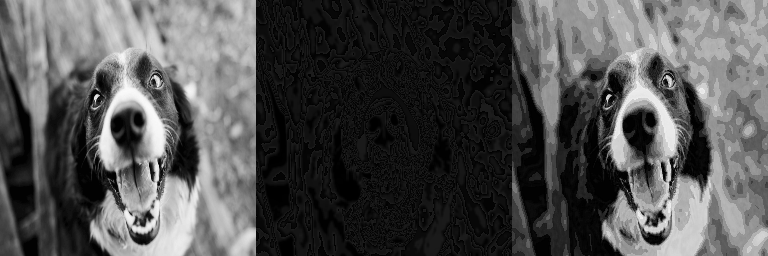

In [52]:
# 1. Load your uploaded file
file_path = 'test.png'
image = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    print(f"Error: Could not find '{file_path}'. Make sure it's uploaded to the folder on the left.")
else:
    # Resize to 256x256 for a faster simulation
    image = cv2.resize(image, (256, 256))

    # 2. Run the hardware simulation
    print("Simulating hardware logic... please wait.")
    approx_result = apply_approx_mean_filter(image)

    # 3. Calculate Quality Metric (PSNR)
    mse = np.mean((image - approx_result) ** 2)
    if mse == 0:
        psnr = 100
    else:
        psnr = 20 * np.log10(255.0 / np.sqrt(mse))

    # 4. Display results
    print(f"Simulation Complete! PSNR: {psnr:.2f} dB")

    # Error map shows exactly where the approximation logic deviated from the original
    error_map = cv2.absdiff(image, approx_result)

    # Stack images: Original | Approximate | Difference
    combined = np.hstack((image, approx_result, error_map))
    cv2_imshow(combined)

In [53]:
from tensorflow.keras.datasets import mnist

# 1. Load the MNIST dataset
(x_train_raw, _), (x_test_raw, _) = mnist.load_data()

# 2. Select 1000 images for training (to save time)
num_samples = 1000
x_train_subset = x_train_raw[:num_samples]

# 3. Apply your hardware simulation to create the 'Targets'
print(f"Generating {num_samples} approximate images... this may take 2-3 minutes.")
y_train_approx = []

for img in x_train_subset:
    # Use the function we created in Cell 3
    approx_img = apply_approx_mean_filter(img)
    y_train_approx.append(approx_img)

y_train_approx = np.array(y_train_approx)

# 4. Normalize the data (Scale 0-255 to 0-1)
# ML models prefer numbers between 0 and 1
x_train_subset = x_train_subset.astype('float32') / 255.0
y_train_approx = y_train_approx.astype('float32') / 255.0

print("Dataset successfully generated!")

Generating 1000 approximate images... this may take 2-3 minutes.
Dataset successfully generated!


In [54]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Build the CNN Architecture
model_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)), # MNIST images are 28x28
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')
])

model_cnn.compile(optimizer='adam', loss='mse')

# 2. Train the Model
print("Training the CNN to learn your approximate logic...")
history = model_cnn.fit(
    x_train_subset.reshape(-1, 28, 28, 1),
    y_train_approx.reshape(-1, 28, 28, 1),
    epochs=10,
    batch_size=16
)

print("Training Complete!")

Training the CNN to learn your approximate logic...
Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.1623
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0411
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0109
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0053
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0035
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0027
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0023
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0020
Epoch 9/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0018
Epoch 10/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0017
Training Complete!


In [55]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [56]:
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric

# 1. Prepare 100 test images using your hardware logic
x_test_subset = x_test_raw[:100].astype('float32') / 255.0
y_test_approx = []

print("Simulating hardware logic on test images...")
for img in x_test_raw[:100]:
    y_test_approx.append(apply_approx_mean_filter(img))

y_test_approx = np.array(y_test_approx).astype('float32') / 255.0

# 2. Let the AI predict the output
predictions = model_cnn.predict(x_test_subset.reshape(-1, 28, 28, 1))
predictions = predictions.reshape(-1, 28, 28) # Reshape for metric calculations

# 3. Calculate all parameters
mse_list, mae_list, psnr_list, ssim_list = [], [], [], []

for i in range(100):
    target = y_test_approx[i]
    pred = predictions[i]

    # Statistical Metrics
    mse_val = np.mean((target - pred)**2)
    mae_val = np.mean(np.abs(target - pred))

    # Image Quality Metrics (data_range=1.0 since we normalized to 0-1)
    psnr_val = psnr_metric(target, pred, data_range=1.0)
    ssim_val = ssim_metric(target, pred, data_range=1.0)

    mse_list.append(mse_val)
    mae_list.append(mae_val)
    psnr_list.append(psnr_val)
    ssim_list.append(ssim_val)

# 4. Print Final Tabulated Results
print(f"\n--- Final CNN Evaluation Metrics ---")
print(f"MSE (Mean Squared Error) ↓:  {np.mean(mse_list):.6f}")
print(f"MAE (Mean Absolute Error) ↓: {np.mean(mae_list):.6f}")
print(f"PSNR (Peak Signal-to-Noise) ↑: {np.mean(psnr_list):.2f} dB")
print(f"SSIM (Structural Similarity) ↑: {np.mean(ssim_list):.4f}")

Simulating hardware logic on test images...
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step

--- Final CNN Evaluation Metrics ---
MSE (Mean Squared Error) ↓:  0.001590
MAE (Mean Absolute Error) ↓: 0.029421
PSNR (Peak Signal-to-Noise) ↑: 28.05 dB
SSIM (Structural Similarity) ↑: 0.2213


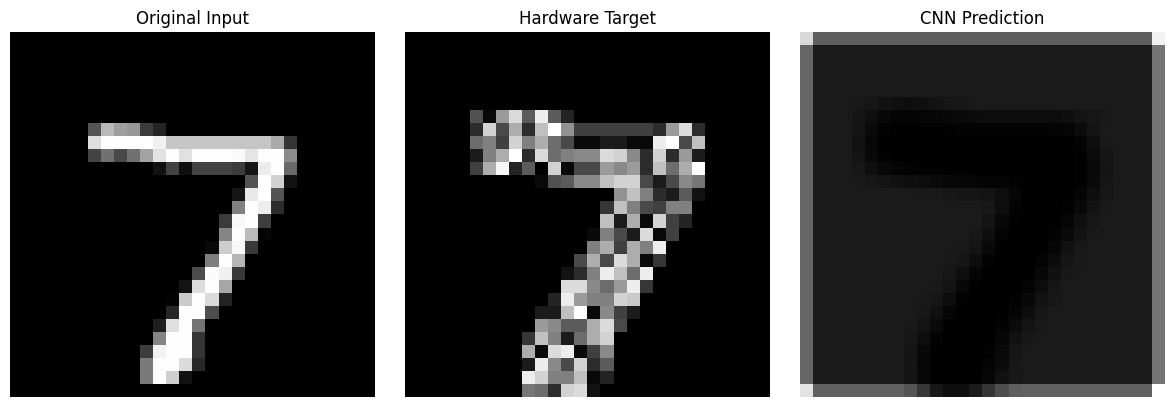

In [57]:
import matplotlib.pyplot as plt

# 1. Generate predictions specifically from the CNN model
# (Make sure x_test_subset is reshaped correctly for the CNN input)
cnn_predictions = model_cnn.predict(x_test_subset.reshape(-1, 28, 28, 1), verbose=0)

# 2. Compare the first test image
plt.figure(figsize=(12, 4))

# Original MNIST Digit
plt.subplot(1, 3, 1)
plt.title("Original Input")
plt.imshow(x_test_subset[0].reshape(28, 28), cmap='gray')
plt.axis('off')

# The output from your approximate hardware logic
plt.subplot(1, 3, 2)
plt.title("Hardware Target")
plt.imshow(y_test_approx[0], cmap='gray')
plt.axis('off')

# The CNN's attempt to mimic the hardware
plt.subplot(1, 3, 3)
plt.title("CNN Prediction")
plt.imshow(cnn_predictions[0].reshape(28, 28), cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

CNN DONE NEXT MLP

In [58]:
model_mlp = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.Dense(784, activation='sigmoid'),
    layers.Reshape((28, 28, 1))
])

model_mlp.compile(optimizer='adam', loss='mse')

print("Training the MLP (Baseline Model)...")
history_mlp = model_mlp.fit(
    x_train_subset.reshape(-1, 28, 28, 1),
    y_train_approx.reshape(-1, 28, 28, 1),
    epochs=10,
    batch_size=16,
    verbose=1
)

Training the MLP (Baseline Model)...
Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0231
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0012
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0012
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0012
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0012
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0012
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0012
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0012
Epoch 9/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0012
Epoch 10/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0012


In [59]:
# 1. Predict using the MLP on unseen data
mlp_preds = model_mlp.predict(x_test_subset.reshape(-1, 28, 28, 1), verbose=0)
mlp_preds = mlp_preds.reshape(-1, 28, 28)

# 2. Calculate the Metrics for your Table
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric

m_mse = np.mean((y_test_approx - mlp_preds)**2)
m_mae = np.mean(np.abs(y_test_approx - mlp_preds))
m_psnr = np.mean([psnr_metric(y_test_approx[i], mlp_preds[i], data_range=1.0) for i in range(100)])
m_ssim = np.mean([ssim_metric(y_test_approx[i], mlp_preds[i], data_range=1.0) for i in range(100)])

print(f"\n--- MLP Results for Research Table ---")
print(f"MSE:  {m_mse:.6f}")
print(f"MAE:  {m_mae:.6f}")
print(f"PSNR: {m_psnr:.2f} dB")
print(f"SSIM: {m_ssim:.4f}")


--- MLP Results for Research Table ---
MSE:  0.001155
MAE:  0.015916
PSNR: 29.52 dB
SSIM: 0.2910


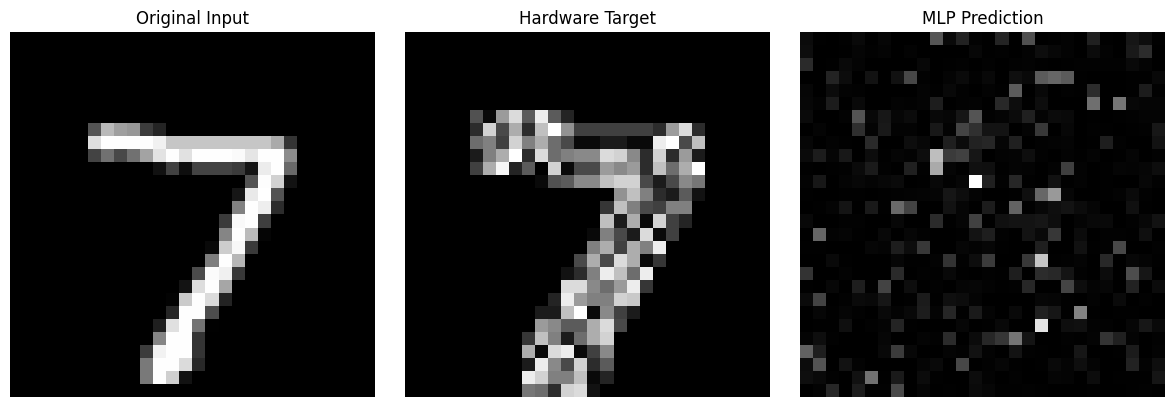

In [60]:
import matplotlib.pyplot as plt

# 1. Ensure you have your MLP predictions ready
# (Using the variable we created in your previous MLP evaluation cell)
# mlp_preds should be the output of model_mlp.predict()

plt.figure(figsize=(12, 4))

# The clean original digit
plt.subplot(1, 3, 1)
plt.title("Original Input")
plt.imshow(x_test_subset[0].reshape(28, 28), cmap='gray')
plt.axis('off')

# The "Ground Truth" from your approximate hardware logic
plt.subplot(1, 3, 2)
plt.title("Hardware Target")
plt.imshow(y_test_approx[0], cmap='gray')
plt.axis('off')

# The MLP's output (This is where you saw the noise earlier)
plt.subplot(1, 3, 3)
plt.title("MLP Prediction")
plt.imshow(mlp_preds[0].reshape(28, 28), cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

MLP done next U-NET

In [61]:
def build_unet():
    inputs = layers.Input(shape=(28, 28, 1))

    # Encoder
    c1 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    # Bottleneck
    c2 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(p1)

    # Decoder with skip connection
    u1 = layers.UpSampling2D((2, 2))(c2)
    concat = layers.Concatenate()([u1, c1])   # ← actual U-Net skip connection
    c3 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(concat)

    # Output
    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid')(c3)

    return models.Model(inputs, outputs)

model_unet = build_unet()
model_unet.compile(optimizer='adam', loss='mse')

print("Training the U-Net (Advanced Reconstruction Model)...")
history_unet = model_unet.fit(
    x_train_subset.reshape(-1, 28, 28, 1),
    y_train_approx.reshape(-1, 28, 28, 1),
    epochs=15,
    batch_size=16,
    verbose=1
)

Training the U-Net (Advanced Reconstruction Model)...
Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step - loss: 0.0289
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - loss: 0.0012
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - loss: 0.0012
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - loss: 0.0012
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 90ms/step - loss: 0.0012
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - loss: 0.0012
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - loss: 0.0012
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - loss: 0.0012
Epoch 9/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 73ms/step - loss: 0.0012
Epoch 10/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - loss: 0.0012
Epoch 11/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.0012
Epoch 12/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.0012
Epoch 13/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 105ms/step - loss: 0.0012
Epoch 14/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.0012
Epoch 15/1

In [62]:
# 1. Predict using the U-Net on unseen data
unet_preds = model_unet.predict(x_test_subset.reshape(-1, 28, 28, 1), verbose=0)
unet_preds = unet_preds.reshape(-1, 28, 28)

# 2. Calculate the Metrics
u_mse = np.mean((y_test_approx - unet_preds)**2)
u_mae = np.mean(np.abs(y_test_approx - unet_preds))
u_psnr = np.mean([psnr_metric(y_test_approx[i], unet_preds[i], data_range=1.0) for i in range(100)])
u_ssim = np.mean([ssim_metric(y_test_approx[i], unet_preds[i], data_range=1.0) for i in range(100)])

print(f"\n--- U-Net Results for Research Table ---")
print(f"MSE:  {u_mse:.6f}")
print(f"MAE:  {u_mae:.6f}")
print(f"PSNR: {u_psnr:.2f} dB")
print(f"SSIM: {u_ssim:.4f}")


--- U-Net Results for Research Table ---
MSE:  0.001156
MAE:  0.016000
PSNR: 29.51 dB
SSIM: 0.2910


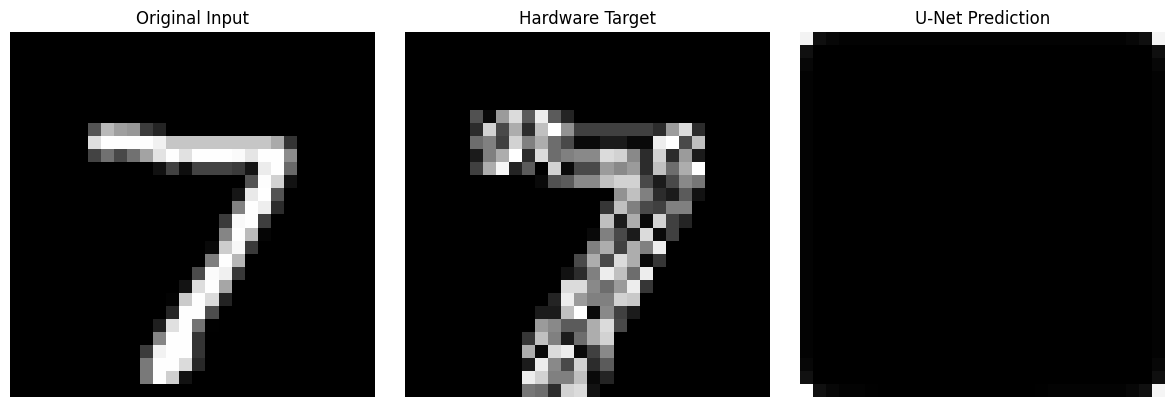

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Original MNIST Digit
plt.subplot(1, 3, 1)
plt.title("Original Input")
plt.imshow(x_test_subset[0].reshape(28, 28), cmap='gray')
plt.axis('off')

# The hardware logic output
plt.subplot(1, 3, 2)
plt.title("Hardware Target")
plt.imshow(y_test_approx[0], cmap='gray')
plt.axis('off')

# The U-Net reconstruction
plt.subplot(1, 3, 3)
plt.title("U-Net Prediction")
plt.imshow(unet_preds[0].reshape(28, 28), cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

   FINAL COMPARISON TABLE — Approximate Hardware Emulation
                     MSE ↓     MAE ↓ PSNR (dB) ↑  SSIM ↑
Model                                                   
MLP (Baseline)    0.001155  0.015916       29.52  0.2910
CNN (Spatial)     0.001590  0.029421       28.05  0.2213
U-Net (Advanced)  0.001156  0.016000       29.51  0.2910
↓ = lower is better    ↑ = higher is better
Test set: 100 MNIST images | Training set: 1000 MNIST images

  Best MSE  → MLP (Baseline)
  Best MAE  → MLP (Baseline)
  Best PSNR → MLP (Baseline)
  Best SSIM → U-Net (Advanced)


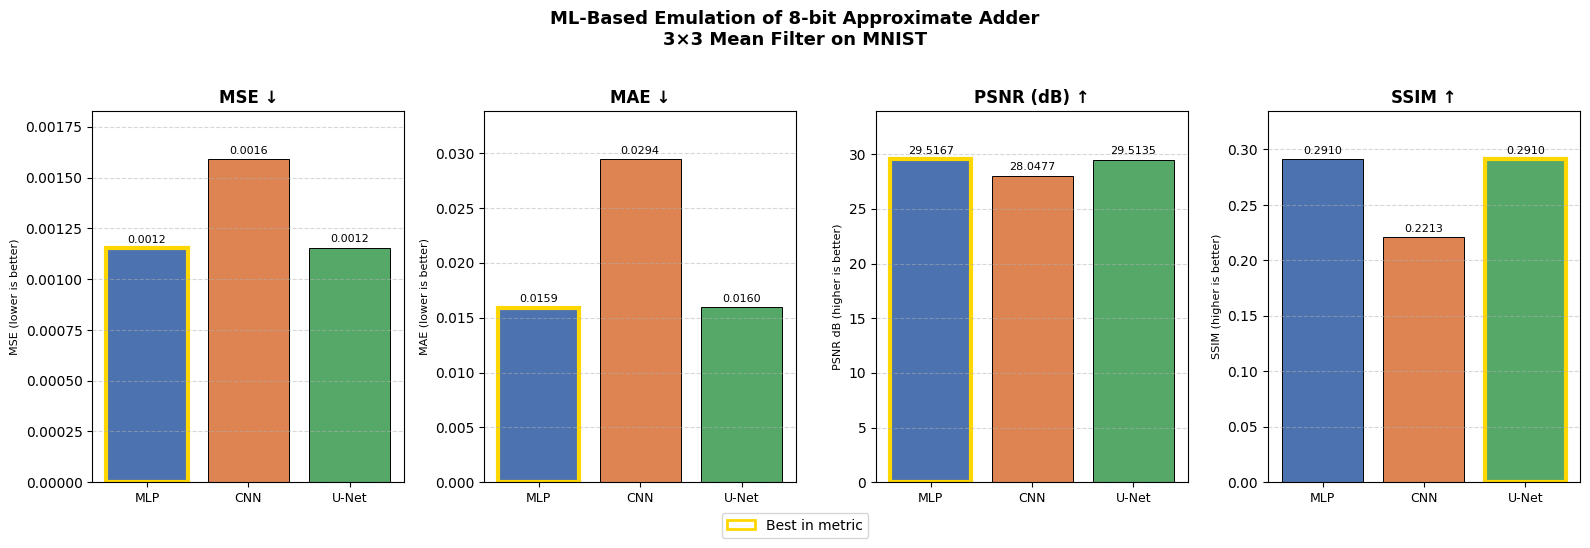


Chart saved as 'comparison_table.png'


In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ─────────────────────────────────────────────
# 1. COLLECT ALL METRICS INTO ONE TABLE
# ─────────────────────────────────────────────

# CNN metrics (already computed in Cell 7)
c_mse  = np.mean(mse_list)
c_mae  = np.mean(mae_list)
c_psnr = np.mean(psnr_list)
c_ssim = np.mean(ssim_list)

# MLP metrics (already computed in Cell 11)
# m_mse, m_mae, m_psnr, m_ssim

# U-Net metrics (already computed in Cell 15)
# u_mse, u_mae, u_psnr, u_ssim

# Build the comparison table
data = {
    "Model"      : ["MLP (Baseline)", "CNN (Spatial)", "U-Net (Advanced)"],
    "MSE ↓"      : [m_mse,  c_mse,  u_mse],
    "MAE ↓"      : [m_mae,  c_mae,  u_mae],
    "PSNR (dB) ↑": [m_psnr, c_psnr, u_psnr],
    "SSIM ↑"     : [m_ssim, c_ssim, u_ssim],
}

df = pd.DataFrame(data).set_index("Model")

# Round for clean display
df_display = df.copy()
df_display["MSE ↓"]       = df_display["MSE ↓"].map("{:.6f}".format)
df_display["MAE ↓"]       = df_display["MAE ↓"].map("{:.6f}".format)
df_display["PSNR (dB) ↑"] = df_display["PSNR (dB) ↑"].map("{:.2f}".format)
df_display["SSIM ↑"]      = df_display["SSIM ↑"].map("{:.4f}".format)

print("=" * 65)
print("   FINAL COMPARISON TABLE — Approximate Hardware Emulation")
print("=" * 65)
print(df_display.to_string())
print("=" * 65)
print("↓ = lower is better    ↑ = higher is better")
print(f"Test set: 100 MNIST images | Training set: 1000 MNIST images")

# ─────────────────────────────────────────────
# 2. HIGHLIGHT THE BEST VALUE IN EACH COLUMN
# ─────────────────────────────────────────────

best_mse  = df["MSE ↓"].idxmin()
best_mae  = df["MAE ↓"].idxmin()
best_psnr = df["PSNR (dB) ↑"].idxmax()
best_ssim = df["SSIM ↑"].idxmax()

print(f"\n  Best MSE  → {best_mse}")
print(f"  Best MAE  → {best_mae}")
print(f"  Best PSNR → {best_psnr}")
print(f"  Best SSIM → {best_ssim}")

# ─────────────────────────────────────────────
# 3. BAR CHART COMPARISON (publication-ready)
# ─────────────────────────────────────────────

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle(
    "ML-Based Emulation of 8-bit Approximate Adder\n3×3 Mean Filter on MNIST",
    fontsize=13, fontweight='bold', y=1.02
)

models   = df.index.tolist()
colors   = ['#4C72B0', '#DD8452', '#55A868']
metrics  = ["MSE ↓", "MAE ↓", "PSNR (dB) ↑", "SSIM ↑"]
ylabels  = ["MSE (lower is better)",
            "MAE (lower is better)",
            "PSNR dB (higher is better)",
            "SSIM (higher is better)"]

for ax, metric, ylabel in zip(axes, metrics, ylabels):
    vals = df[metric].values
    bars = ax.bar(models, vals, color=colors, edgecolor='black', linewidth=0.7)

    # Highlight best bar with a star
    if "↓" in metric:
        best_idx = int(np.argmin(vals))
    else:
        best_idx = int(np.argmax(vals))
    bars[best_idx].set_edgecolor('gold')
    bars[best_idx].set_linewidth(3)

    # Value labels on bars
    for bar, val in zip(bars, vals):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(vals) * 0.01,
            f"{val:.4f}", ha='center', va='bottom', fontsize=8
        )

    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=8)
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(["MLP", "CNN", "U-Net"], fontsize=9)
    ax.set_ylim(0, max(vals) * 1.15)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

gold_patch = mpatches.Patch(edgecolor='gold', facecolor='white',
                             linewidth=2, label='Best in metric')
fig.legend(handles=[gold_patch], loc='lower center',
           ncol=1, bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()
plt.savefig("comparison_table.png", dpi=150, bbox_inches='tight')
plt.show()
print("\nChart saved as 'comparison_table.png'")

/tmp/ipykernel_910/2861618281.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap


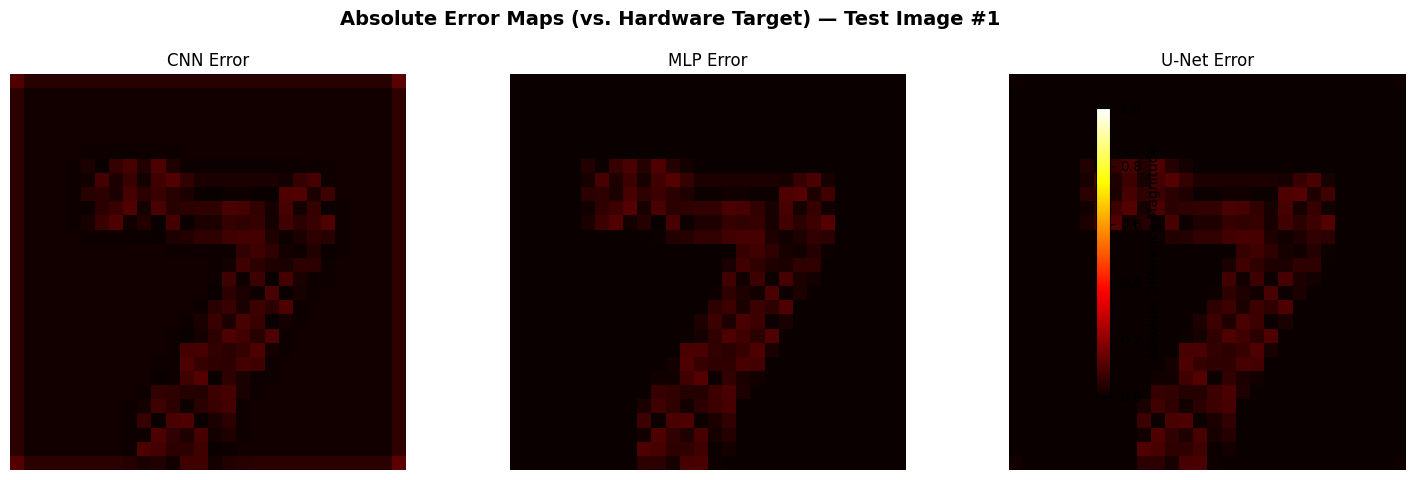

Error map comparison saved as 'error_map_comparison.png'


In [65]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate absolute error maps for the first test image
# Ensure cnn_predictions, mlp_preds, and unet_preds are reshaped correctly
error_cnn = np.abs(y_test_approx[0] - cnn_predictions[0].reshape(28, 28))
error_mlp = np.abs(y_test_approx[0] - mlp_preds[0].reshape(28, 28))
error_unet = np.abs(y_test_approx[0] - unet_preds[0].reshape(28, 28))

fig3, axes3 = plt.subplots(1, 3, figsize=(15, 5))
fig3.suptitle("Absolute Error Maps (vs. Hardware Target) — Test Image #1", fontsize=14, fontweight='bold')

error_maps = [error_cnn, error_mlp, error_unet]
model_names = ["CNN Error", "MLP Error", "U-Net Error"]

for ax, error_map, title in zip(axes3, error_maps, model_names):
    # Using 'hot' colormap or similar to highlight differences, 'gray' would make it hard to see
    im = ax.imshow(error_map, cmap='hot', vmin=0, vmax=1) # vmin/vmax for consistent scaling
    ax.set_title(title, fontsize=12)
    ax.axis('off')

# Add a colorbar for better interpretation of error magnitudes
fig3.colorbar(im, ax=axes3.ravel().tolist(), orientation='vertical', shrink=0.75, label='Absolute Difference Magnitude')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.savefig("error_map_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print("Error map comparison saved as 'error_map_comparison.png'")

Applying exact mean filter...
Applying approximate mean filter...

PSNR (Original vs. Approximate Filter): 28.22 dB
PSNR (Exact Filter vs. Approximate Filter): 30.62 dB


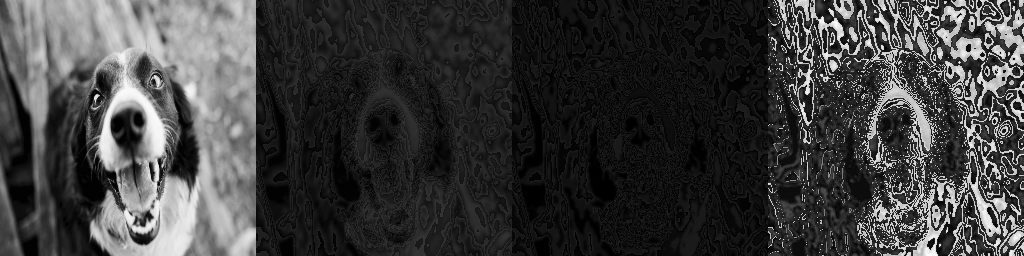

Displayed: Original | Exact Filter | Approximate Filter | Absolute Error Map (Exact vs Approx)


In [66]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow # Special function for Colab to show images

# Load the image (assuming 'test.png' is available)
file_path = 'test.png'
image = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    print(f"Error: Could not find '{file_path}'. Make sure it's uploaded to the folder on the left.")
else:
    # Resize to 256x256 for consistency and faster simulation
    image = cv2.resize(image, (256, 256))

    print("Applying exact mean filter...")
    exact_result = apply_exact_mean_filter(image)
    print("Applying approximate mean filter...")
    approx_result = apply_approx_mean_filter(image)

    # Calculate PSNR between original and approximate result
    mse_approx_orig = np.mean((image - approx_result) ** 2)
    psnr_approx_orig = 20 * np.log10(255.0 / np.sqrt(mse_approx_orig)) if mse_approx_orig != 0 else 100

    # Calculate PSNR between exact and approximate filtered images
    mse_exact_approx = np.mean((exact_result - approx_result) ** 2)
    psnr_exact_approx = 20 * np.log10(255.0 / np.sqrt(mse_exact_approx)) if mse_exact_approx != 0 else 100

    # Error map shows exactly where the approximation logic deviated from the exact filter
    error_map_abs = cv2.absdiff(exact_result, approx_result)
    error_map_display = cv2.normalize(error_map_abs, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)

    print(f"\nPSNR (Original vs. Approximate Filter): {psnr_approx_orig:.2f} dB")
    print(f"PSNR (Exact Filter vs. Approximate Filter): {psnr_exact_approx:.2f} dB")

    # Stack images: Original | Exact Filter | Approximate Filter | Error Map
    combined_comparison = np.hstack((image, exact_result, approx_result, error_map_display))

    cv2_imshow(combined_comparison)
    print("Displayed: Original | Exact Filter | Approximate Filter | Absolute Error Map (Exact vs Approx)")

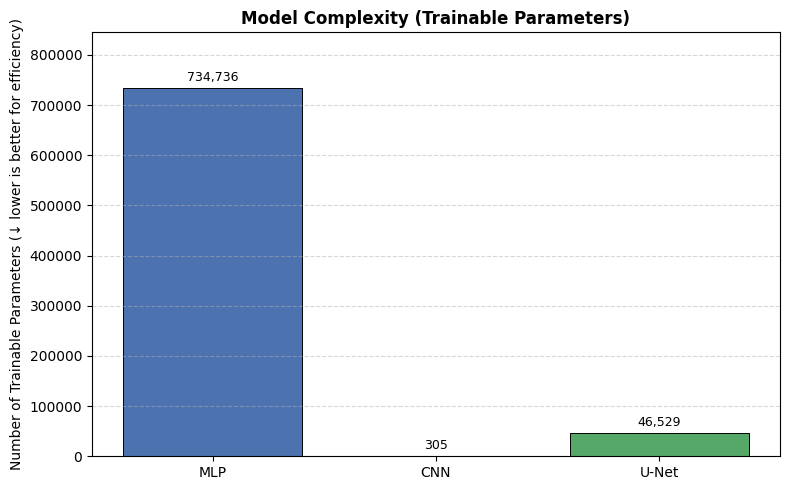

Model complexity comparison saved as 'model_complexity_comparison.png'


In [67]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Get the number of trainable parameters for each model
cnn_params = model_cnn.count_params()
mlp_params = model_mlp.count_params()
unet_params = model_unet.count_params()

# Create a DataFrame for easy plotting
param_data = {
    'Model': ['MLP (Baseline)', 'CNN (Spatial)', 'U-Net (Advanced)'],
    'Trainable Parameters': [mlp_params, cnn_params, unet_params]
}
df_params = pd.DataFrame(param_data)

# Plotting
fig, ax = plt.subplots(figsize=(8, 5))

models = df_params['Model'].tolist()
params = df_params['Trainable Parameters'].tolist()
colors = ['#4C72B0', '#DD8452', '#55A868'] # Consistent colors

bars = ax.bar(models, params, color=colors, edgecolor='black', linewidth=0.7)

# Value labels on bars
for bar, val in zip(bars, params):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(params) * 0.01,
        f"{val:,}", ha='center', va='bottom', fontsize=9
    )

ax.set_title("Model Complexity (Trainable Parameters)", fontweight='bold')
ax.set_ylabel("Number of Trainable Parameters (↓ lower is better for efficiency)")
ax.set_xticks(range(len(models)))
ax.set_xticklabels(["MLP", "CNN", "U-Net"], fontsize=10)
ax.set_ylim(0, max(params) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("model_complexity_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print("Model complexity comparison saved as 'model_complexity_comparison.png'")

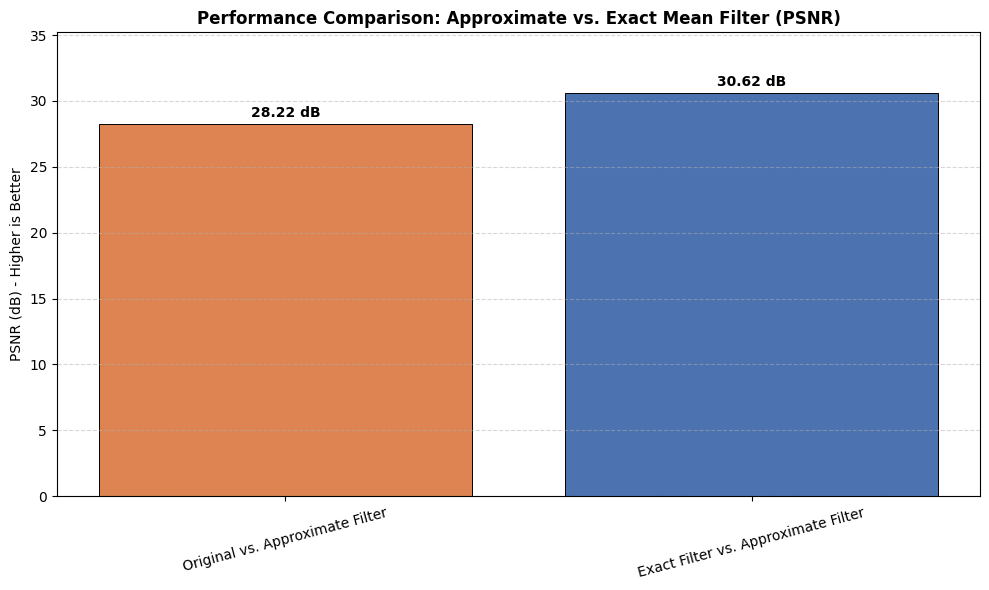

Performance comparison graph saved as 'approx_vs_exact_performance.png'

Summary of PSNR values:

PSNR (Original vs. Approximate Filter): 28.22 dB
PSNR (Exact Filter vs. Approximate Filter): 30.62 dB


In [68]:
import matplotlib.pyplot as plt
import numpy as np

# Retrieve the PSNR values calculated previously in cell 'a8af30ee'
# If the previous cell wasn't run, these variables would be undefined.
# Assuming they are available from the kernel state:
# psnr_approx_orig: PSNR (Original vs. Approximate Filter)
# psnr_exact_approx: PSNR (Exact Filter vs. Approximate Filter)

labels = ['Original vs. Approximate Filter', 'Exact Filter vs. Approximate Filter']
psnr_values = [psnr_approx_orig, psnr_exact_approx]
colors = ['#DD8452', '#4C72B0']

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(labels, psnr_values, color=colors, edgecolor='black', linewidth=0.7)

# Value labels on bars
for bar, val in zip(bars, psnr_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(psnr_values) * 0.01,
        f"{val:.2f} dB", ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax.set_title("Performance Comparison: Approximate vs. Exact Mean Filter (PSNR)", fontweight='bold')
ax.set_ylabel("PSNR (dB) - Higher is Better")
ax.set_ylim(0, max(psnr_values) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig("approx_vs_exact_performance.png", dpi=150, bbox_inches='tight')
plt.show()

print("Performance comparison graph saved as 'approx_vs_exact_performance.png'")

print(f"\nSummary of PSNR values:\n")
print(f"PSNR (Original vs. Approximate Filter): {psnr_approx_orig:.2f} dB")
print(f"PSNR (Exact Filter vs. Approximate Filter): {psnr_exact_approx:.2f} dB")

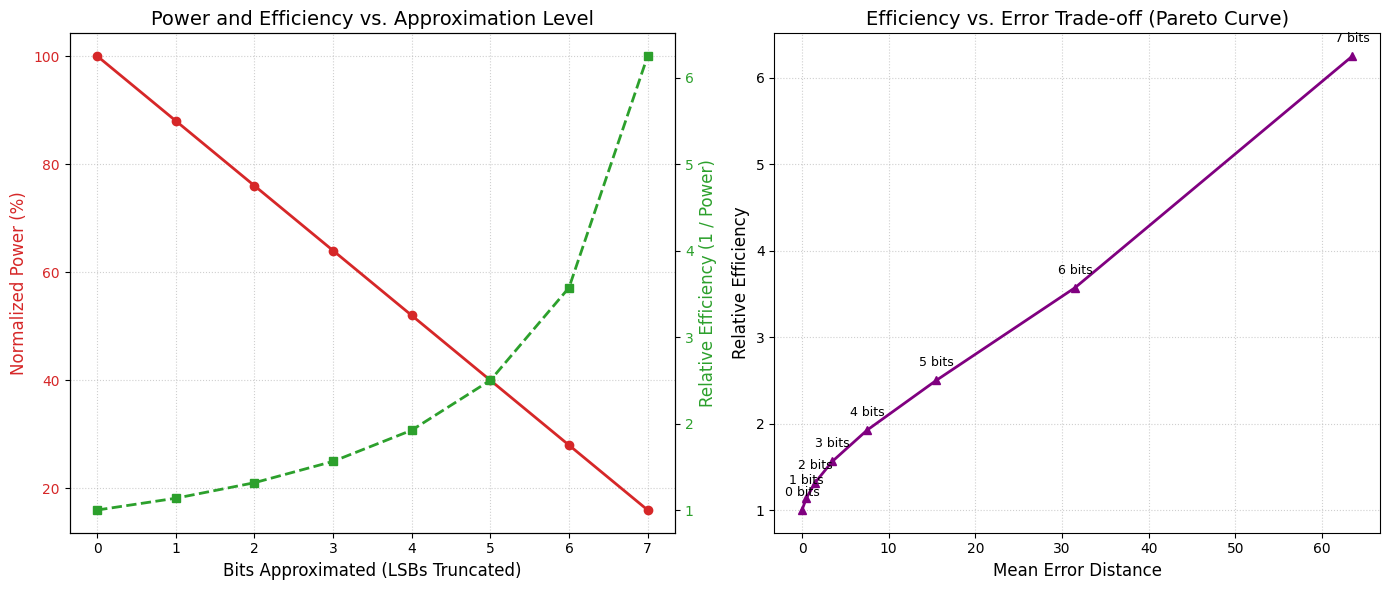

In [69]:
import matplotlib.pyplot as plt
import numpy as np

# Approximation levels (Bits truncated from 0 to 7)
# (Stopping at 7 to avoid the unrealistic case of a 0-gate adder)
bits_approximated = np.arange(0, 8)

# Theoretical Normalized Power (%)
# Assuming a base standard 8-bit RCA where each bit is roughly 12% of the power,
# leaving a small base overhead for wiring/routing.
power_percent = 100 - (12 * bits_approximated)

# Efficiency (Defined as the inverse of power consumption, normalized to Exact = 1.0)
# This represents how many additions you can do for a fixed energy budget.
efficiency = 100 / power_percent

# Mean Error Distance
mean_error = [(2**n - 1) / 2 for n in bits_approximated]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Graph 1: Power & Efficiency vs Bits Approximated
color1 = 'tab:red'
ax1.set_xlabel('Bits Approximated (LSBs Truncated)', fontsize=12)
ax1.set_ylabel('Normalized Power (%)', color=color1, fontsize=12)
ax1.plot(bits_approximated, power_percent, marker='o', color=color1, linewidth=2, label='Power')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(bits_approximated)

ax1_twin = ax1.twinx()
color2 = 'tab:green'
ax1_twin.set_ylabel('Relative Efficiency (1 / Power)', color=color2, fontsize=12)
ax1_twin.plot(bits_approximated, efficiency, marker='s', linestyle='--', color=color2, linewidth=2, label='Efficiency')
ax1_twin.tick_params(axis='y', labelcolor=color2)

ax1.set_title("Power and Efficiency vs. Approximation Level", fontsize=14)
ax1.grid(True, linestyle=':', alpha=0.6)

# Graph 2: Efficiency vs Mean Error (Pareto Curve)
ax2.plot(mean_error, efficiency, marker='^', color='purple', linewidth=2)
ax2.set_xlabel('Mean Error Distance', fontsize=12)
ax2.set_ylabel('Relative Efficiency', fontsize=12)
ax2.set_title("Efficiency vs. Error Trade-off (Pareto Curve)", fontsize=14)
ax2.grid(True, linestyle=':', alpha=0.6)

# Annotate points on the Pareto curve
for i, txt in enumerate(bits_approximated):
    ax2.annotate(f"{txt} bits", (mean_error[i], efficiency[i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('efficiency_tradeoff.png', dpi=150)